# Merton Jump-Diffusion Simulation


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Model parameters
S0 = 80
K = 80
r = 0.055
sigma = 0.35
T = 0.25

# Jump parameters
mu = -0.5
delta = 0.22

# Monte Carlo settings
simulations = 100000
steps = 100
dt = T/steps

In [ ]:
def simulate_jump_diffusion(S0, r, sigma, T, mu, delta, lam, steps, sims):

    dt = T/steps
    k = np.exp(mu + 0.5*delta**2) - 1

    prices = np.zeros((sims, steps))
    prices[:,0] = S0

    for t in range(1, steps):

        Z = np.random.normal(size=sims)
        poisson = np.random.poisson(lam*dt, sims)

        jump = np.exp(mu + delta*np.random.normal(size=sims)) - 1

        prices[:,t] = prices[:,t-1] * np.exp((r - lam*k - 0.5*sigma**2)*dt +
                       sigma*np.sqrt(dt)*Z) * (1 + jump*poisson)

    return prices

In [ ]:
lam = 0.75

paths = simulate_jump_diffusion(S0, r, sigma, T, mu, delta, lam, steps, simulations)

ST = paths[:,-1]

call_payoff = np.maximum(ST-K,0)
put_payoff = np.maximum(K-ST,0)

call_price = np.exp(-r*T)*np.mean(call_payoff)
put_price = np.exp(-r*T)*np.mean(put_payoff)

print("Call Price:", call_price)
print("Put Price:", put_price)

Call Price: 8.255579366808737
Put Price: 7.157415802382983


In [ ]:
lam = 0.25

paths = simulate_jump_diffusion(S0, r, sigma, T, mu, delta, lam, steps, simulations)

ST = paths[:,-1]

call_payoff = np.maximum(ST-K,0)
put_payoff = np.maximum(K-ST,0)

call_price2 = np.exp(-r*T)*np.mean(call_payoff)
put_price2 = np.exp(-r*T)*np.mean(put_payoff)

print("Call Price:", call_price2)
print("Put Price:", put_price2)

Call Price: 6.741571495178309
Put Price: 5.70490411761091


In [ ]:
epsilon = 1

def option_price(S):

    paths = simulate_jump_diffusion(S, r, sigma, T, mu, delta, lam, steps, simulations)
    ST = paths[:,-1]
    payoff = np.maximum(ST-K,0)

    return np.exp(-r*T)*np.mean(payoff)

C = option_price(S0)
C_up = option_price(S0+epsilon)
C_down = option_price(S0-epsilon)

delta = (C_up - C_down)/(2*epsilon)
gamma = (C_up - 2*C + C_down)/(epsilon**2)

print("Delta:",delta)
print("Gamma:",gamma)

Delta: 0.5891585333492846
Gamma: 0.07574335675384969


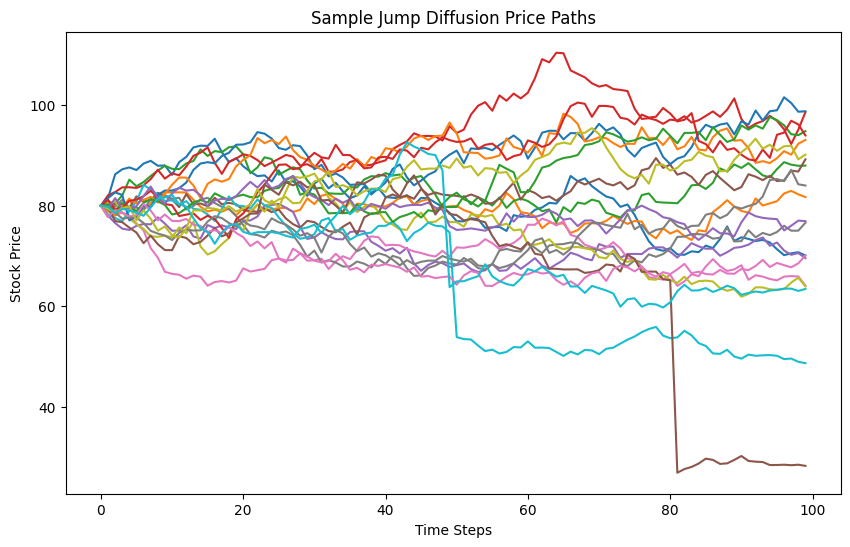

In [ ]:
plt.figure(figsize=(10,6))

for i in range(20):
    plt.plot(paths[i])

plt.title("Sample Jump Diffusion Price Paths")
plt.xlabel("Time Steps")
plt.ylabel("Stock Price")
plt.show()

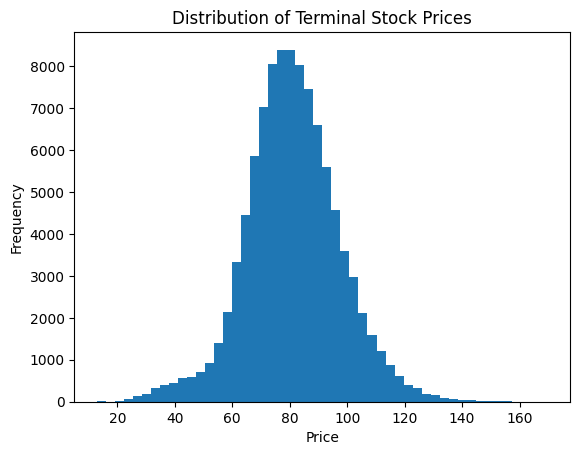

In [ ]:
plt.hist(ST, bins=50)
plt.title("Distribution of Terminal Stock Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

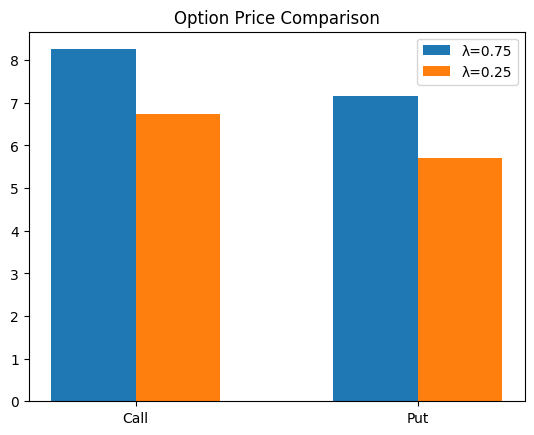

In [ ]:
labels = ['Call','Put']
lambda075 = [call_price, put_price]
lambda025 = [call_price2, put_price2]

x = np.arange(len(labels))

plt.bar(x-0.15, lambda075, width=0.3,label='λ=0.75')
plt.bar(x+0.15, lambda025, width=0.3,label='λ=0.25')

plt.xticks(x,labels)
plt.title("Option Price Comparison")
plt.legend()
plt.show()

In [ ]:
# Merton Jump Diffusion Model using Monte Carlo

# Import required libraries
import numpy as np
import pandas as pd

# Model Parameters

S0 = 80            # Initial stock price
K = 80             # Strike price (ATM)
r = 0.055          # Risk-free interest rate
sigma = 0.35       # Volatility
T = 0.25           # Time to maturity (years)

# Jump parameters
mu_jump = -0.5     # Mean jump size
delta_jump = 0.22  # Jump volatility

# Simulation parameters
n_simulations = 100000
n_steps = 100


# Function: Simulate Merton Jump Diffusion Paths

def simulate_merton_jump_paths(S0, r, sigma, T,
                               mu_jump, delta_jump, lam,
                               n_steps, n_simulations):
    """
    Simulates stock price paths using the Merton Jump Diffusion Model.

    Parameters
    ----------
    S0 : float
        Initial stock price
    r : float
        Risk-free rate
    sigma : float
        Volatility
    T : float
        Time to maturity
    mu_jump : float
        Mean jump size
    delta_jump : float
        Jump size volatility
    lam : float
        Jump intensity (average number of jumps per year)
    n_steps : int
        Number of time steps
    n_simulations : int
        Number of Monte Carlo paths

    Returns
    -------
    paths : numpy array
        Simulated stock price paths
    """

    dt = T / n_steps

    # Expected jump size adjustment
    k = np.exp(mu_jump + 0.5 * delta_jump**2) - 1

    # Initialize price paths
    paths = np.zeros((n_simulations, n_steps + 1))
    paths[:, 0] = S0

    # Simulate paths
    for t in range(1, n_steps + 1):

        # Brownian motion component
        Z = np.random.normal(0, 1, n_simulations)

        diffusion = np.exp((r - lam * k - 0.5 * sigma**2) * dt +
                           sigma * np.sqrt(dt) * Z)

        # Poisson jump component
        poisson_jump = np.random.poisson(lam * dt, n_simulations)

        jump_size = np.exp(mu_jump + delta_jump *
                           np.random.normal(size=n_simulations))

        jump = jump_size ** poisson_jump

        # Update price
        paths[:, t] = paths[:, t-1] * diffusion * jump

    return paths


# Function: Price European Call and Put

def price_european_options(paths, K, r, T):
    """
    Calculates European call and put prices
    from simulated terminal stock prices.
    """

    # Terminal prices
    ST = paths[:, -1]

    # Payoffs
    call_payoff = np.maximum(ST - K, 0)
    put_payoff = np.maximum(K - ST, 0)

    # Discount expected payoff
    call_price = np.exp(-r * T) * np.mean(call_payoff)
    put_price = np.exp(-r * T) * np.mean(put_payoff)

    return call_price, put_price


# Run Simulation Example
lambda_jump = 0.75

paths = simulate_merton_jump_paths(
    S0, r, sigma, T,
    mu_jump, delta_jump,
    lambda_jump,
    n_steps,
    n_simulations
)

call_price, put_price = price_european_options(paths, K, r, T)

# Store results in dataframe
results = pd.DataFrame({
    "Option": ["European Call", "European Put"],
    "Price": [call_price, put_price]
})

print("Jump Intensity (λ) =", lambda_jump)
print(results)

Jump Intensity (λ) = 0.75
          Option     Price
0  European Call  8.247684
1   European Put  7.225781


## Merton Jump Diffusion Pricing (λ = 0.75)


In [ ]:
import numpy as np
import pandas as pd

# Model Parameters

S0 = 80
K = 80
r = 0.055
sigma = 0.35
T = 0.25

# Jump parameters
mu_jump = -0.5
delta_jump = 0.22

# Simulation settings
n_simulations = 100000
n_steps = 100
dt = T / n_steps
lambda_jump = 0.75


# Function to simulate jump diffusion paths

def simulate_merton_jump_paths(S0, r, sigma, T,
                               mu_jump, delta_jump, lam,
                               n_steps, n_simulations):

    dt = T / n_steps

    # Expected jump size adjustment
    k = np.exp(mu_jump + 0.5 * delta_jump**2) - 1

    # Initialize price matrix
    paths = np.zeros((n_simulations, n_steps + 1))
    paths[:, 0] = S0

    for t in range(1, n_steps + 1):

        # Brownian motion
        Z = np.random.normal(0, 1, n_simulations)

        diffusion = np.exp((r - lam * k - 0.5 * sigma**2) * dt +
                           sigma * np.sqrt(dt) * Z)

        # Poisson jumps
        poisson_jump = np.random.poisson(lam * dt, n_simulations)

        jump_size = np.exp(mu_jump + delta_jump *
                           np.random.normal(size=n_simulations))

        jump = jump_size ** poisson_jump

        # Price update
        paths[:, t] = paths[:, t-1] * diffusion * jump

    return paths


# Option Pricing Function

def price_options(paths, K, r, T):

    ST = paths[:, -1]

    call_payoff = np.maximum(ST - K, 0)
    put_payoff = np.maximum(K - ST, 0)

    call_price = np.exp(-r * T) * np.mean(call_payoff)
    put_price = np.exp(-r * T) * np.mean(put_payoff)

    return call_price, put_price


# Run Simulation

paths = simulate_merton_jump_paths(
    S0, r, sigma, T,
    mu_jump, delta_jump,
    lambda_jump,
    n_steps,
    n_simulations
)

call_price, put_price = price_options(paths, K, r, T)


# Results Table

results = pd.DataFrame({
    "Option Type": ["European Call", "European Put"],
    "Price": [round(call_price, 2), round(put_price, 2)]
})

print("Jump Intensity (λ) =", lambda_jump)
print(results)


Jump Intensity (λ) = 0.75
     Option Type  Price
0  European Call   8.26
1   European Put   7.27


In [ ]:
import numpy as np
import pandas as pd

# Model Parameters

S0 = 80
K = 80
r = 0.055
sigma = 0.35
T = 0.25

# Jump parameters
mu_jump = -0.5
delta_jump = 0.22

# Simulation settings
n_simulations = 100000
n_steps = 100
lambda_jump_q9 = 0.25


# Simulate Jump Diffusion Paths

def simulate_merton_jump_paths(S0, r, sigma, T,
                               mu_jump, delta_jump, lam,
                               n_steps, n_simulations):

    dt = T / n_steps

    k = np.exp(mu_jump + 0.5 * delta_jump**2) - 1

    paths = np.zeros((n_simulations, n_steps + 1))
    paths[:, 0] = S0

    for t in range(1, n_steps + 1):

        Z = np.random.normal(0, 1, n_simulations)

        diffusion = np.exp((r - lam * k - 0.5 * sigma**2) * dt +
                           sigma * np.sqrt(dt) * Z)

        poisson_jump = np.random.poisson(lam * dt, n_simulations)

        jump_size = np.exp(mu_jump + delta_jump *
                           np.random.normal(size=n_simulations))

        jump = jump_size ** poisson_jump

        paths[:, t] = paths[:, t-1] * diffusion * jump

    return paths


# Option Pricing Function

def price_options(paths, K, r, T):

    ST = paths[:, -1]

    call_payoff = np.maximum(ST - K, 0)
    put_payoff = np.maximum(K - ST, 0)

    call_price = np.exp(-r * T) * np.mean(call_payoff)
    put_price = np.exp(-r * T) * np.mean(put_payoff)

    return call_price, put_price


# Run Simulation

paths_q9 = simulate_merton_jump_paths(
    S0, r, sigma, T,
    mu_jump, delta_jump,
    lambda_jump_q9,
    n_steps,
    n_simulations
)

call_q9, put_q9 = price_options(paths_q9, K, r, T)


# Results Table

results_q9 = pd.DataFrame({
    "Option Type": ["European Call", "European Put"],
    "Price": [round(call_q9, 2), round(put_q9, 2)]
})

print("Jump Intensity (λ) =", lambda_jump_q9)
print(results_q9)


Jump Intensity (λ) = 0.25
     Option Type  Price
0  European Call   6.84
1   European Put   5.71


## Greeks from Finite Differences


In [ ]:
import numpy as np
import pandas as pd

# Parameters
S0 = 80
K = 80
r = 0.055
sigma = 0.35
T = 0.25

mu_jump = -0.5
delta_jump = 0.22

n_simulations = 100000
n_steps = 100

lambda_jump = 0.75   # using the same lambda as 

h = 1  # small change in stock price


# Jump Diffusion Simulation

def simulate_paths(S0):

    dt = T / n_steps
    k = np.exp(mu_jump + 0.5 * delta_jump**2) - 1

    paths = np.zeros((n_simulations, n_steps + 1))
    paths[:,0] = S0

    for t in range(1, n_steps + 1):

        Z = np.random.normal(size=n_simulations)

        diffusion = np.exp((r - lambda_jump*k - 0.5*sigma**2)*dt +
                           sigma*np.sqrt(dt)*Z)

        poisson_jump = np.random.poisson(lambda_jump*dt, n_simulations)

        jump_size = np.exp(mu_jump + delta_jump *
                           np.random.normal(size=n_simulations))

        jump = jump_size ** poisson_jump

        paths[:,t] = paths[:,t-1] * diffusion * jump

    return paths


# Option pricing

def option_prices(S):

    paths = simulate_paths(S)

    ST = paths[:,-1]

    call = np.exp(-r*T) * np.mean(np.maximum(ST-K,0))
    put = np.exp(-r*T) * np.mean(np.maximum(K-ST,0))

    return call, put


# Compute prices at S, S+h, S-h

C, P = option_prices(S0)

C_up, P_up = option_prices(S0 + h)
C_down, P_down = option_prices(S0 - h)


# Delta

delta_call = (C_up - C_down) / (2*h)
delta_put = (P_up - P_down) / (2*h)


# Gamma

gamma_call = (C_up - 2*C + C_down) / (h**2)
gamma_put = (P_up - 2*P + P_down) / (h**2)


# Results Table

greeks = pd.DataFrame({
    "Option": ["Call", "Put"],
    "Delta": [round(delta_call,4), round(delta_put,4)],
    "Gamma": [round(gamma_call,4), round(gamma_put,4)]
})

print(greeks)


  Option   Delta   Gamma
0   Call  0.6712  0.1820
1    Put -0.3625 -0.0749


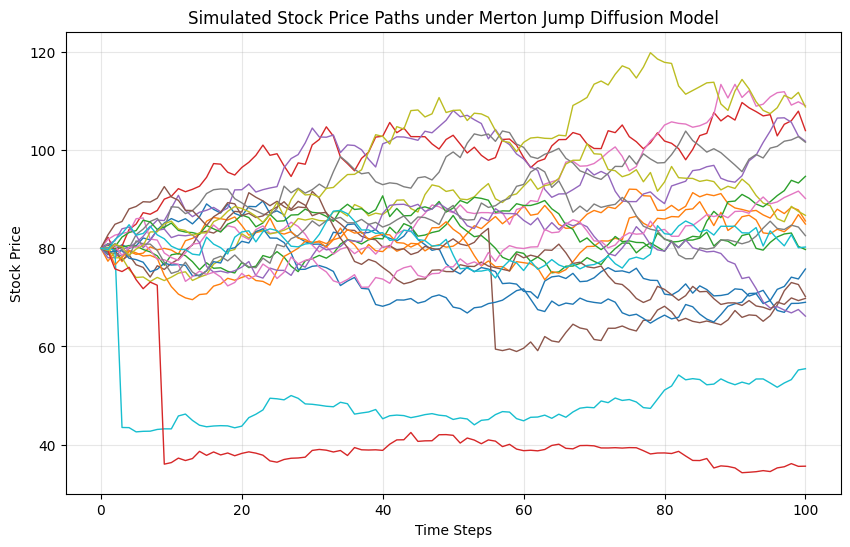

In [ ]:
# Graph 1: Simulated Stock Price Paths

import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

# Plot first 20 simulated paths
for i in range(20):
    plt.plot(paths[i], linewidth=1)

plt.title("Simulated Stock Price Paths under Merton Jump Diffusion Model")
plt.xlabel("Time Steps")
plt.ylabel("Stock Price")

plt.grid(alpha=0.3)

plt.show()

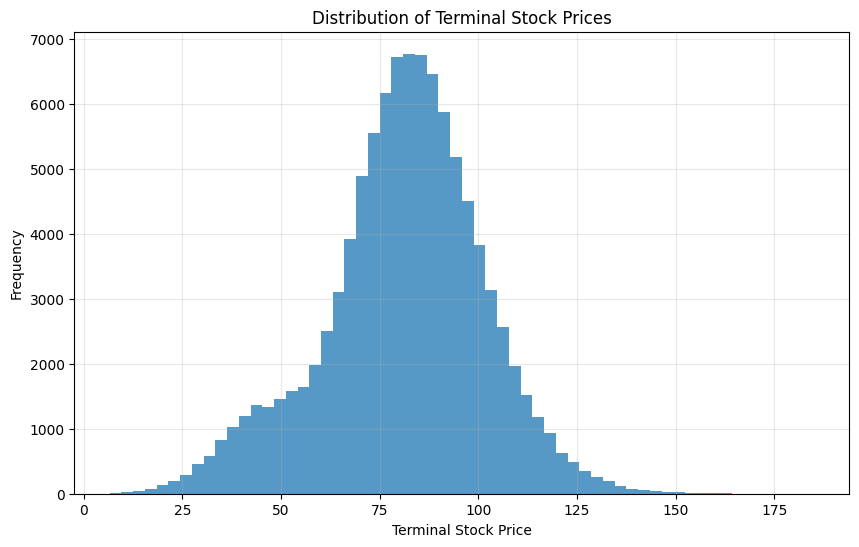

In [ ]:
# Graph 2: Distribution of Terminal Prices

ST = paths[:, -1]

plt.figure(figsize=(10,6))

plt.hist(ST, bins=60, alpha=0.75)

plt.title("Distribution of Terminal Stock Prices")
plt.xlabel("Terminal Stock Price")
plt.ylabel("Frequency")

plt.grid(alpha=0.3)

plt.show()

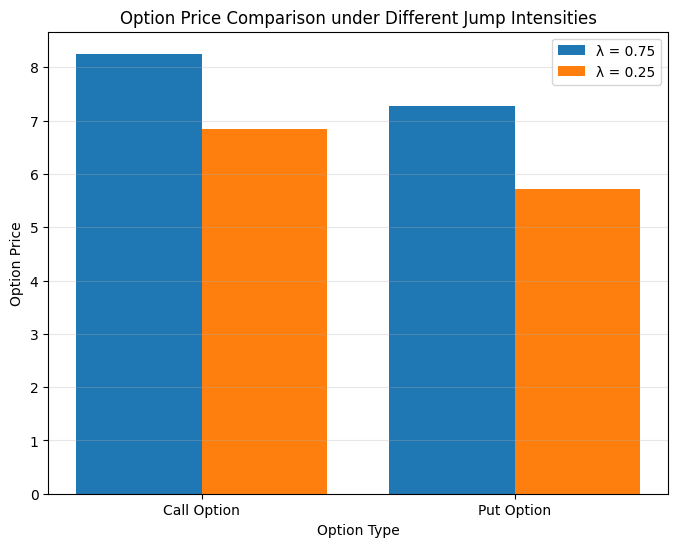

In [ ]:
# Graph 3: Option Price Comparison

labels = ["Call Option", "Put Option"]

lambda_075 = [call_price, put_price]
lambda_025 = [call_q9, put_q9]

import numpy as np

x = np.arange(len(labels))

plt.figure(figsize=(8,6))

plt.bar(x - 0.2, lambda_075, width=0.4, label="λ = 0.75")
plt.bar(x + 0.2, lambda_025, width=0.4, label="λ = 0.25")

plt.xticks(x, labels)

plt.title("Option Price Comparison under Different Jump Intensities")
plt.xlabel("Option Type")
plt.ylabel("Option Price")

plt.legend()

plt.grid(axis='y', alpha=0.3)

plt.show()

In [ ]:
# Heston Model – Up-and-In Barrier Option

import numpy as np
import pandas as pd

# Given Parameters

S0 = 80
K = 95
B = 95
r = 0.055
T = 0.25

# Heston parameters (from )
v0 = 0.032       # 3.2%
kappa = 1.85
theta = 0.045
xi = 0.5         # assumed (if not given)
rho = -0.70

# Simulation settings
steps = 100
sims = 100000
dt = T / steps

# Monte Carlo Simulation

call_payoffs = []
barrier_payoffs = []

for i in range(sims):

    S = S0
    v = v0
    hit_barrier = False

    for t in range(steps):

        Z1 = np.random.normal()
        Z2 = rho * Z1 + np.sqrt(1 - rho**2) * np.random.normal()

        # Variance process
        v = abs(v + kappa * (theta - v) * dt + xi * np.sqrt(v * dt) * Z2)

        # Stock process
        S = S * np.exp((r - 0.5 * v) * dt + np.sqrt(v * dt) * Z1)

        # Check barrier
        if S >= B:
            hit_barrier = True

    ST = S

    # European Call
    call_payoffs.append(max(ST - K, 0))

    # Up-and-In Call
    if hit_barrier:
        barrier_payoffs.append(max(ST - K, 0))
    else:
        barrier_payoffs.append(0)

# Discounting

call_price = np.exp(-r*T) * np.mean(call_payoffs)
barrier_price = np.exp(-r*T) * np.mean(barrier_payoffs)

# Results Table

results = pd.DataFrame({
    "Option": ["European Call", "Up-and-In Call"],
    "Price": [round(call_price, 4), round(barrier_price, 4)]
})

print(results)

           Option   Price
0   European Call  0.0028
1  Up-and-In Call  0.0028
